In [ ]:
from scipy.spatial import Delaunay
import os
import argparse
from glob import glob

import numpy as np
import pandas as pd
from tifffile import imread

from matplotlib import pyplot as plt

from matplotlib.lines import Line2D

color_palette = ["#FF2BD6", "#FF7A00", "#39FF14", "#00E5FF", "#B388FF"]

In [2]:
pick_well = "A1"
pick_site = "1"
base_dir = "C:/Users/shery/Documents/bioinfo_windows/ARCOS-triangulate/data"

DIR_OUT_DATA = "output-data"
DIR_OUT_PLOT = "output-plots"

SAMPLE_OUT_DIR = f"{DIR_OUT_DATA}/well_{pick_well}_site_{pick_site}"
DIR_OUT_PLOT = f"{DIR_OUT_PLOT}/well_{pick_well}_site_{pick_site}"
os.makedirs(DIR_OUT_PLOT, exist_ok=True)

os.chdir("C:/Users/shery/Documents/bioinfo_windows/ARCOS-triangulate/")

In [3]:
try:
    # Load raw images
    np_nuc = imread(glob(os.path.join(base_dir, f"Well{pick_well}_Seq*_Site{pick_site}_C1*.tif"))[0])
    np_erk = imread(glob(os.path.join(base_dir, f"Well{pick_well}_Seq*_Site{pick_site}_C3*.tif"))[0])

    # Load saved results
    np_lab_filt = np.load(f"{SAMPLE_OUT_DIR}/np_lab_large.npz")["arr"]
    np_lab_ring = np.load(f"{SAMPLE_OUT_DIR}/np_lab_ring.npz")["arr"]

    df_tracks = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_tracks.csv.gz", compression="gzip")
    df_arcos_data = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_arcos_data.csv.gz", compression="gzip")
    df_ce = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce.csv.gz", compression="gzip")
    df_ce_filt = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce_filt.csv.gz", compression="gzip")
    df_ce_stats = pd.read_csv(f"{SAMPLE_OUT_DIR}/df_ce_stats.csv.gz", compression="gzip")
    df_ce_points = pd.read_csv(f"{SAMPLE_OUT_DIR}/ce_points.csv")

    print(f"Successfully loaded image stacks and outputs for {SAMPLE_OUT_DIR}!")
except Exception as e:
    print(f"Failed to load: {e}")

# umm i just want to invert the erk
np_erk = np_erk.max() + np_erk.min() - np_erk

Successfully loaded image stacks and outputs for output-data/well_A1_site_1!


In [4]:
np_lab_ring_meas = np.load(f"{SAMPLE_OUT_DIR}/np_lab_ring_meas.npz")["arr"]

### Constants

In [5]:
n_frame_show = 1
n_layers = 2

display(df_arcos_data)

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin
0,0,124,922.547746,696.155080,5434.708174,4843.657609,2,0.891245,0.000000,0.000000,0
1,1,64,918.625977,705.525391,3961.966797,2857.135897,2,0.721141,0.083333,0.000000,0
2,2,127,922.197446,704.499018,3823.117878,2737.850282,2,0.716130,0.166667,0.000000,0
3,3,130,924.901587,704.820106,3903.353439,2782.088050,2,0.712743,0.250000,0.000000,0
4,4,83,924.850669,701.572606,3867.683831,2801.118033,2,0.724237,0.333333,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...
207053,523,302,38.429612,794.458738,6933.541262,6560.403279,3859,0.946184,43.583333,0.007467,0
207054,524,310,38.104326,794.646310,6973.083969,6630.907591,3859,0.950929,43.666667,0.001840,0
207055,525,264,36.144703,795.948320,6908.767442,6461.254717,3859,0.935225,43.750000,0.000000,0
207056,526,263,36.402667,796.477333,6908.650667,6415.925806,3859,0.928680,43.833333,0.000000,0


### Some functions for plotting the scipy Delaunay

In [139]:
def plot_cell_ids(points, tri, image=None, xlim=None, ylim=None, figsize=(10, 10), labels=None):
    """Draw the mesh and write a label next to every cell, to help you choose cells by number.

    points : (n, 2) array of x, y coordinates; row i is vertex i
    tri    : the Delaunay object built from exactly these points
    image  : optional background image
    xlim, ylim : zoom window. Only cells inside it are labelled. Give ylim largest value first
                 (e.g. (700, 450)) because imshow puts y = 0 at the top.
    labels : the column itself, one entry per point, e.g. labels=arcos_frame["track_id"].
             Default None prints the vertex ids (row positions within this frame).
    """
    # --- check the inputs agree with each other before drawing anything ---
    assert len(points) == tri.npoints, f"{len(points)} points but triangulation has {tri.npoints}"
    if isinstance(labels, str):
        raise TypeError("pass the column itself, e.g. labels=arcos_frame['track_id'], not its name")
    # np.asarray -> plain array, so lab[v] is by position and not by a (possibly different) pandas index;
    # we keep `labels` itself because the title reads its .name
    lab = None if labels is None else np.asarray(labels)
    if lab is not None:
        assert len(lab) == len(points), "labels must have one entry per point"

    # --- background, mesh and cell dots ---
    fig, ax = plt.subplots(figsize=figsize)
    if image is not None:
        ax.imshow(image, cmap="Greys", interpolation="none", vmin=image.min(), vmax=image.max())
    ax.triplot(points[:, 0], points[:, 1], tri.simplices, alpha=0.3, linewidth=0.5, color="yellow")
    ax.plot(points[:, 0], points[:, 1], 'o', markersize=3)

    # --- zoom, and work out which cells fall inside the window (only those get text) ---
    inside = np.ones(len(points), bool)         # start with every cell labelled
    if xlim:
        inside &= (points[:, 0] >= min(xlim)) & (points[:, 0] <= max(xlim))
        ax.set_xlim(xlim)
    if ylim:
        inside &= (points[:, 1] >= min(ylim)) & (points[:, 1] <= max(ylim))
        ax.set_ylim(ylim)                       # keep the order given, so the reversed y stays reversed

    # --- write one label per visible cell, nudged up and right so it doesn't sit on the dot ---
    for v in np.where(inside)[0]:
        txt = str(lab[v]) if lab is not None else str(v)
        ax.annotate(txt, points[v], fontsize=7, xytext=(3, 3), textcoords="offset points", color="lightgrey")

    # title: the Series name if one was passed (e.g. "track_id"), otherwise a generic description
    ax.set_title(getattr(labels, "name", None) or ("Vertex IDs" if labels is None else "Custom labels"))

    return fig, ax


def plot_layers(points, tri, tri_layers, image=None, show_mesh=True, labels="track_id",
                xlim=None, ylim=None, figsize=(8, 8), title=None, ax=None, legend=True, vmin=None, vmax=None, cmap=color_palette, size=30, legend_max=4):
    """Draw all cells in grey and the selected cells coloured by layer (layer 0 = picked, outlined).

    points     : (n, 2) array of x, y coordinates; row i is vertex i
    tri        : the Delaunay object built from exactly these points
    tri_layers : table of the selected cells with columns vertex, layer (plus e.g. track_id)
    labels     : name of a tri_layers column to print next to each selected cell
                 ("track_id", "vertex", ...), or None for no text.
    ax         : draw into this existing axes (used for montages); if None a new figure is made
    legend     : show the layer colour legend
    """
    # --- check inputs ---
    assert len(points) == tri.npoints, f"{len(points)} points but triangulation has {tri.npoints}"
    selected = tri_layers.drop_duplicates("vertex")          # one row per selected cell

    # vertex -> layer
    layer_of = selected.set_index("vertex")["layer"]
    n_layers = int(layer_of.max()) if len(layer_of) else 0

    # colormap...
    palette = lambda l: cmap[l % len(cmap)]

    # --- figure: new one, or the axes we were given ---
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # --- background, mesh, and every cell as a light grey dot ---
    if image is not None:
        ax.imshow(image, cmap="Greys", interpolation="none",
                  vmin=image.min() if vmin is None else vmin,
                  vmax=image.max() if vmax is None else vmax)
    if show_mesh:
        ax.triplot(points[:, 0], points[:, 1], tri.simplices, alpha=0.3, linewidth=0.5, color="yellow")
    ax.plot(points[:, 0], points[:, 1], 'o', markersize=size**0.5/2, color="lightgrey", zorder=2)

    # --- selected cells, drawn layer by layer in that layer's colour ---
    # zorder makes inner layers sit on top of outer ones
    for l in range(n_layers + 1):
        ids = layer_of.index[layer_of == l].to_numpy()      # vertex ids in this layer
        if len(ids) == 0:
            continue
        ax.scatter(points[ids, 0], points[ids, 1], s=size, color=palette(l), zorder=3 + (n_layers - l))

    # --- text next to each selected cell: the chosen column's value, placed at that cell's coordinates ---
    if labels is not None:
        for v, text in zip(selected["vertex"], selected[labels]):
            ax.annotate(str(text), points[v], fontsize=7, xytext=(3, 3),
                        textcoords="offset points", zorder=10, color="lightgrey")

    # --- legend, zoom, title ---
    handles = [Line2D([], [], marker="o", ls="", color=palette(l),
                      label="core cells" if l == 0 else f"{l}-step") for l in range(legend_max)]
    if legend:
        ax.legend(handles=handles, loc="upper right")
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    ax.set_title(title or f"Selection expanded by {n_layers} Delaunay layer(s)")
    return fig, ax

# Initialize Delaunay objects

In [140]:
np_nuc_show = np_nuc[n_frame_show]
np_erk_show = np_erk[n_frame_show]

np_arcos_coords = df_arcos_data[df_arcos_data['t'] == n_frame_show][['x','y']].values
tri_points = np_arcos_coords

# Compute Delaunay triangulation
tri = Delaunay(tri_points)

# Compute Delaunay neighbor vertices
indptr, indices = tri.vertex_neighbor_vertices

Look at the track IDs

['t', 'obj_id', 'x', 'y', 'intensity_mean_nuc', 'intensity_mean_cyto', 'track_id', 'cnr', 'rt', 'cnr.resc', 'cnr.bin', 'cl_id_x', 'cl_id_y']


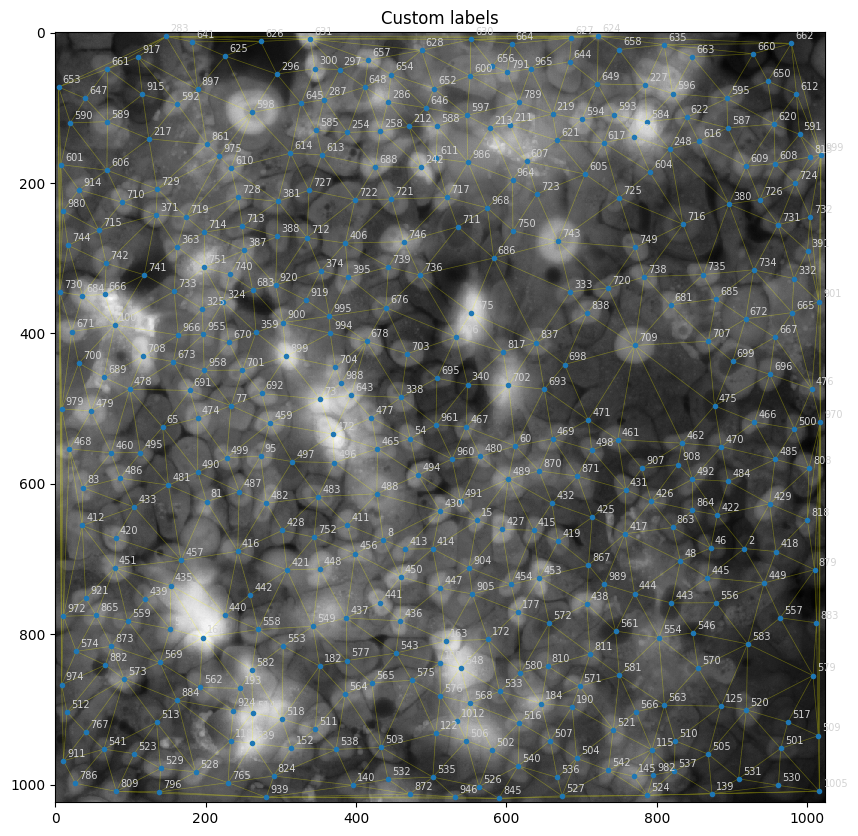

In [141]:
# Plot
tri_frame = df_arcos_data[df_arcos_data['t'] == n_frame_show].reset_index(drop=True)   # row i == vertex i
assert len(tri_frame) == len(tri_points)

tri_id_col = "track_id"   # e.g. "track_id" / "trackID" -- whatever identifies a cell in df_arcos_data
print(tri_frame.columns.tolist())

# look at the IDs
plot_cell_ids(tri_points, tri, image=np_erk_show,
              labels=tri_frame[tri_id_col].to_numpy())
plt.show()

In [142]:
# Pick your track IDs, then convert to vertex IDs
picked_track = [570, 563]

picked_v = tri_frame.index[tri_frame['track_id'].isin(picked_track)].tolist()
print(f"picked track IDs: {picked_track}")
print(f"these correspond to vertex IDs: {picked_v}")

picked track IDs: [570, 563]
these correspond to vertex IDs: [191, 197]


# Building Delaunay neighbors

## Scipy djikstra
- Uses a CSR matrix (compressed matrix) which is the same output returned by tri.vertex_neighbor_vertices (indptr and indices?)
- Djikstra algorithm: find shortest path from starting note to every other node
    - unweighted=True: ignore values in matrix, treat every edge as cost 1, so distance is purely based on # of edges. Dropping this would return distance along the mesh in pixels (real distances)
    - indices=picked_v: starting point
    - min_only=True: runs from all the start vertices ("picked" cells) at the same time. For each cell, return the shortest distance from whichever "picked" cell is nearest, to avoid redundant repeat paths. If false we would get one row of distances per picked cell

In [143]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# user picks track IDs, convert to vertex IDs
picked_track = [421]
picked_v = tri_frame.index[tri_frame['track_id'].isin(picked_track)].tolist()

print(f"picked track IDs: {picked_track}")
print(f"these correspond to vertex IDs: {picked_v}")

# adj: csr matrix with these two arrays plus an empty column of ones
adj = csr_matrix((np.ones(len(indices)), indices, indptr), shape=(len(tri_points),) * 2)

dijk_hops = dijkstra(adj, unweighted=True, indices=picked_v, min_only=True, limit=n_layers)   # hops from the nearest picked cell, search will end after n_layers neighbors
tri_frame['layer'] = dijk_hops # both hops and tri_frame are built along vertex ID, so they join properly                                              
# inf = not reachable

# return df of the core cells and their n neighbor layers. filter at n_layers to omit inf cells
picked_neighbors = tri_frame[tri_frame['layer'] <= n_layers].copy()
# dijk returns as float, which could be useful if we switch to using real distance, but convert to int for now
picked_neighbors['layer'] = picked_neighbors['layer'].astype(int)

display(picked_neighbors.head())

picked track IDs: [421]
these correspond to vertex IDs: [73]


,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id_x,cl_id_y,layer
1,24,126,436.196868,674.263982,10626.351230,8694.185083,8,0.818172,2.0,0.022559,0,NaN,NaN,3
7,24,12,142.742495,524.532355,6725.719813,6640.009494,65,0.987256,2.0,0.113452,0,NaN,NaN,4
9,24,184,233.828269,496.016254,9500.304594,9279.355634,77,0.976743,2.0,0.236701,0,NaN,NaN,4
10,24,193,201.320949,623.556244,10475.519092,7379.372043,81,0.704440,2.0,0.013269,0,NaN,NaN,2
11,24,298,36.828037,604.989720,11199.380374,8863.390244,83,0.791418,2.0,0.039309,0,NaN,NaN,4


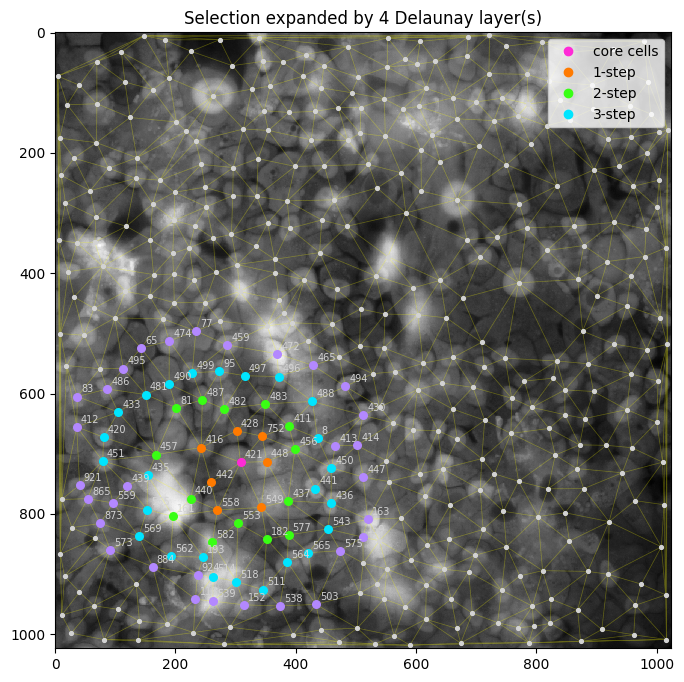

In [144]:
# prepare picked_neighbors for display with plot_layers function
picked_neighbors_layers = picked_neighbors.rename_axis('vertex').reset_index()
picked_neighbors_layers = picked_neighbors_layers[["vertex", "layer", "x", "y", "track_id"]]

fig, ax = plot_layers(tri_points, tri, picked_neighbors_layers, image=np_erk_show)
plt.show()

# Run it all as one function

In [145]:
def delaunay_per_frame(arcos_frame, picked_track, n_layers, max_dist):
    assert arcos_frame['t'].nunique() == 1, "pass exactly one frame at a time"
    arcos_frame = arcos_frame.reset_index(drop=True)      # new table: vertex id == row position
    arcos_frame['vertex'] = arcos_frame.index

    # convert track ids to vertex ids
    picked_v = arcos_frame.loc[arcos_frame['track_id'].isin(picked_track), 'vertex'].to_numpy()
    missing = sorted(set(picked_track) - set(arcos_frame['track_id']))

    print(f"picked track IDs: {picked_track}")
    print(f"these correspond to vertex IDs: {picked_v}")
    if missing:
        print(f"not present in this frame: {missing}")

    if len(picked_v) == 0:        # track missing
        return None, None
    pts = arcos_frame[['x', 'y']].to_numpy()

    # make delaunay object (takes the longest)
    tri = Delaunay(pts)
    indptr, indices = tri.vertex_neighbor_vertices

    # make csr object, remove edges that are too long
    adj = csr_matrix((np.ones(len(indices)), indices, indptr), shape=(len(pts),) * 2).tocoo()
    length = np.hypot(*(pts[adj.row] - pts[adj.col]).T)
    keep = length <= max_dist
    adj = csr_matrix((np.ones(keep.sum()), (adj.row[keep], adj.col[keep])), shape=adj.shape)

    # run dijkstra
    hops = dijkstra(adj, unweighted=True, indices=picked_v, min_only=True, limit=n_layers)

    # clean df for output
    keep = np.isfinite(hops)
    out = arcos_frame.loc[keep, ['vertex', 't', 'track_id', 'x', 'y']].copy()
    out['layer'] = hops[keep].astype(int)
    return out, tri

picked track IDs: [570, 563]
these correspond to vertex IDs: [216 222]


,vertex,layer,x,y,track_id
16,16,1,792.106155,952.969670,115
20,20,1,907.904145,928.002591,125
23,23,2,768.845349,995.991860,145
24,24,2,794.288845,999.547809,146
108,108,2,815.814602,750.316653,443


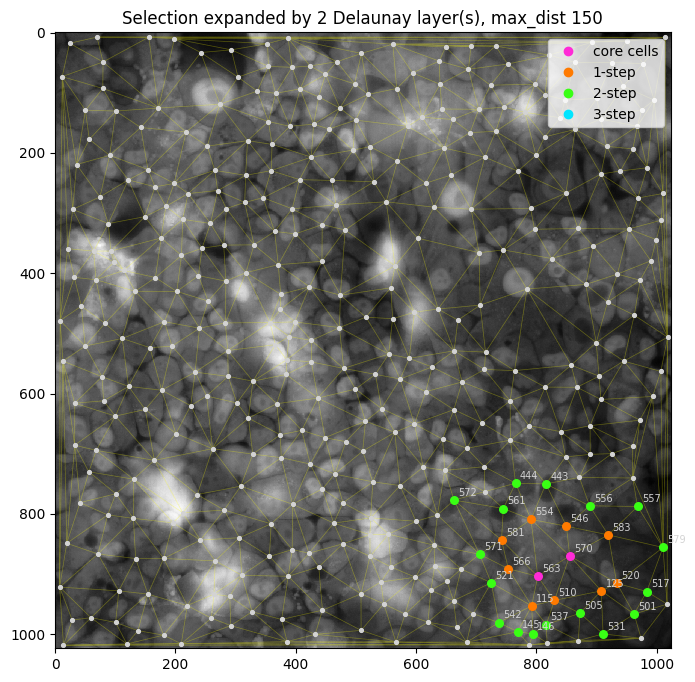

In [146]:
n_frame_show = 5
n_layers = 2
max_dist = 150
picked_track = [570, 563]

test_df_arcos = df_arcos_data[df_arcos_data['t'] == n_frame_show]
test, test_tri = delaunay_per_frame(test_df_arcos, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

# prepare for display with plot_layers function
test_layers = test[["vertex", "layer", "x", "y", "track_id"]]

display(test_layers.head())

np_arcos_coords = df_arcos_data[df_arcos_data['t'] == n_frame_show][['x','y']].values

fig, ax = plot_layers(test_tri.points, test_tri, test_layers, image=np_erk_show, labels="track_id")
ax.set_title(f"Selection expanded by {n_layers} Delaunay layer(s), max_dist {max_dist}")
plt.show()

# Watch neighbors over time (also overlay nuclear masks)

picked track IDs: [570, 563]
these correspond to vertex IDs: [215 221]
picked track IDs: [570, 563]
these correspond to vertex IDs: [207 213]
picked track IDs: [570, 563]
these correspond to vertex IDs: [200 206]
picked track IDs: [570, 563]
these correspond to vertex IDs: [197 203]
picked track IDs: [570, 563]
these correspond to vertex IDs: [195 201]
picked track IDs: [570, 563]
these correspond to vertex IDs: [195 201]
picked track IDs: [570, 563]
these correspond to vertex IDs: [194 200]
picked track IDs: [570, 563]
these correspond to vertex IDs: [191 197]
picked track IDs: [570, 563]
these correspond to vertex IDs: [191 197]
picked track IDs: [570, 563]
these correspond to vertex IDs: [188 194]
picked track IDs: [570, 563]
these correspond to vertex IDs: [186 192]
picked track IDs: [570, 563]
these correspond to vertex IDs: [186 192]
picked track IDs: [570, 563]
these correspond to vertex IDs: [186 192]
picked track IDs: [570, 563]
these correspond to vertex IDs: [186 192]
picked

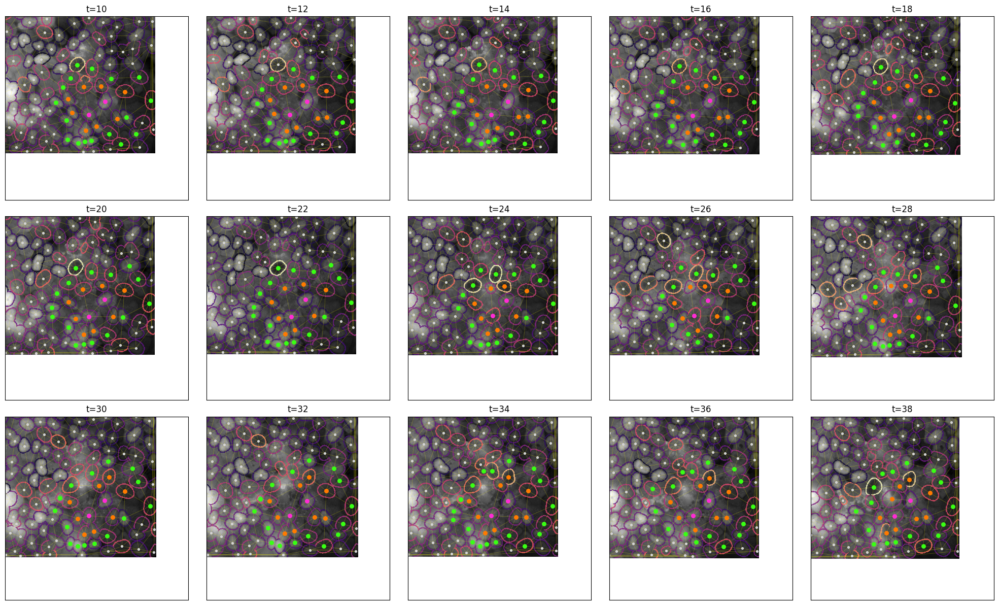

In [147]:
frames = range(10, 40, 2)
ncols = 5
nrows = int(np.ceil(len(frames) / ncols))
# pixels around the picked cell; set to None for full frame
zoom = 300

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

for ax, n_frame in zip(axes.ravel(), frames):
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    out, tri = delaunay_per_frame(frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

    if out is None:                          # track not in this frame
        ax.set_title(f"t={n_frame}: track not found")
        ax.axis('off')
        continue

    kw = {}
    if zoom:
        cx, cy = out.loc[out['layer'] == 0, ['x', 'y']].mean()
        kw = dict(xlim=(cx - zoom, cx + zoom), ylim=(cy + zoom, cy - zoom))   # y reversed for imshow

    plot_layers(tri.points, tri, out, image=np_erk[n_frame], labels=None,
                ax=ax, legend=False, title=f"t={n_frame}", **kw)
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none")

for ax in axes.ravel()[len(frames):]:        # hide unused panels
    ax.axis('off')

plt.tight_layout()
plt.show()

# Watch neighbors even after it dies

In [148]:
def layers_from_tracks(arcos_frame, layer_by_track):
    """Mark cells in this frame using layers remembered from an earlier frame (matched by track_id)."""
    f = arcos_frame.reset_index(drop=True)
    f['vertex'] = f.index
    f['layer'] = f['track_id'].map(layer_by_track)
    out = f.loc[f['layer'].notna(), ['vertex', 't', 'track_id', 'x', 'y', 'layer']].copy()
    out['layer'] = out['layer'].astype(int)
    tri = Delaunay(f[['x', 'y']].to_numpy())
    return out, tri

picked track IDs: [570, 563]
these correspond to vertex IDs: [150 154]
picked track IDs: [570, 563]
these correspond to vertex IDs: [145 149]
picked track IDs: [570, 563]
these correspond to vertex IDs: [144 148]
picked track IDs: [570, 563]
these correspond to vertex IDs: [142 146]
picked track IDs: [570, 563]
these correspond to vertex IDs: [138 142]
picked track IDs: [570, 563]
these correspond to vertex IDs: [136 140]
picked track IDs: [570, 563]
these correspond to vertex IDs: [138]
not present in this frame: [563]
picked track IDs: [570, 563]
these correspond to vertex IDs: [135]
not present in this frame: [563]
picked track IDs: [570, 563]
these correspond to vertex IDs: [132]
not present in this frame: [563]
picked track IDs: [570, 563]
these correspond to vertex IDs: [128]
not present in this frame: [563]
picked track IDs: [570, 563]
these correspond to vertex IDs: [124]
not present in this frame: [563]
picked track IDs: [570, 563]
these correspond to vertex IDs: [122]
not pre

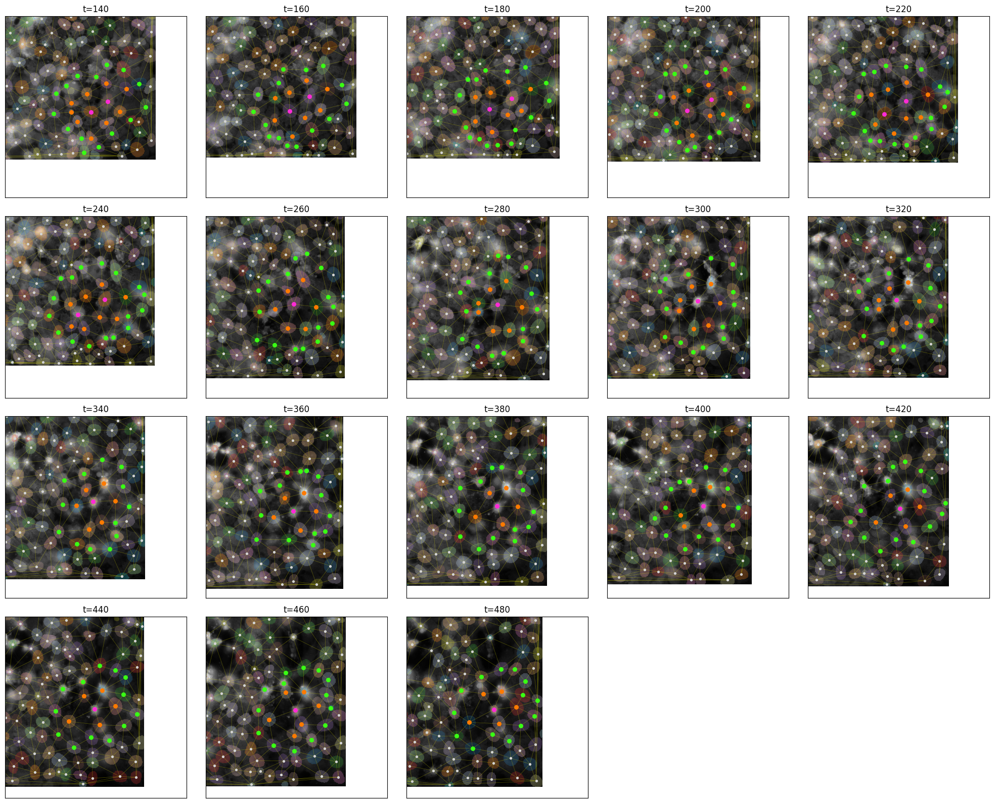

In [149]:
frames = range(140, 500, 20)
ncols = 5
nrows = int(np.ceil(len(frames) / ncols))
zoom = 300                                   # pixels around the selection; None = full frame

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

layer_by_track = None                        # last known {track_id: layer}

for ax, n_frame in zip(axes.ravel(), frames):
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    out, tri = delaunay_per_frame(frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)
    note = ""

    if out is not None:                      # track found: remember its neighborhood
        layer_by_track = dict(zip(out['track_id'], out['layer']))
    elif layer_by_track is not None:         # track lost: reuse the last known neighbors
        out, tri = layers_from_tracks(frame, layer_by_track)
        note = " (track lost: last known neighbors)"

    if out is None or out.empty:             # never found yet, or all neighbors gone too
        ax.set_title(f"t={n_frame}: nothing to show")
        ax.axis('off')
        continue

    kw = {}
    if zoom:
        cx, cy = out[['x', 'y']].mean()      # center on whatever is currently selected
        kw = dict(xlim=(cx - zoom, cx + zoom), ylim=(cy + zoom, cy - zoom))   # y reversed for imshow

    plot_layers(tri.points, tri, out, image=np_erk[n_frame], labels=None,
                ax=ax, legend=False, title=f"t={n_frame}{note}", **kw)
    ax.set_xticks([]); ax.set_yticks([])

    # add nuclear masks
    lab = np_lab_filt[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="tab20", alpha=0.25, interpolation="none")

for ax in axes.ravel()[len(frames):]:        # hide unused panels
    ax.axis('off')

plt.tight_layout()
plt.show()

# Now try on actual binarized CEs

,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id
148,24,95,885.558301,895.698842,5686.922008,5233.522772,125,0.920273,2.000000,0.496922,1,10
153,24,8,757.718812,666.397030,8443.367327,7945.320721,417,0.941013,2.000000,0.579464,1,10
154,24,175,713.988018,644.554839,5359.541935,5984.085664,425,1.116529,2.000000,0.564141,1,10
156,24,128,819.512315,758.406404,5800.326765,8550.483498,443,1.474138,2.000000,1.000000,1,10
157,24,53,942.784359,731.759371,6195.050902,5027.902400,449,0.811600,2.000000,0.526157,1,10
...,...,...,...,...,...,...,...,...,...,...,...,...
392,34,8,752.240000,658.223590,8072.366154,8622.860324,417,1.068195,2.833333,0.722362,1,10
395,34,280,808.407407,742.282900,6567.218282,7937.153153,443,1.208602,2.833333,0.426198,1,10
399,34,30,862.161260,762.531047,4904.717331,6134.076271,556,1.250648,2.833333,0.452229,1,10
412,34,355,657.401408,844.549296,10524.669014,11350.544850,810,1.078470,2.833333,0.843120,1,10


,t,obj_id,x,y,intensity_mean_nuc,intensity_mean_cyto,track_id,cnr,rt,cnr.resc,cnr.bin,cl_id
148,24,95,885.558301,895.698842,5686.922008,5233.522772,125,0.920273,2.0,0.496922,1,10
153,24,8,757.718812,666.397030,8443.367327,7945.320721,417,0.941013,2.0,0.579464,1,10
154,24,175,713.988018,644.554839,5359.541935,5984.085664,425,1.116529,2.0,0.564141,1,10
156,24,128,819.512315,758.406404,5800.326765,8550.483498,443,1.474138,2.0,1.000000,1,10
157,24,53,942.784359,731.759371,6195.050902,5027.902400,449,0.811600,2.0,0.526157,1,10
158,24,170,824.316534,941.707339,6591.673740,6148.341463,510,0.932744,2.0,0.469943,1,10
159,24,242,847.885151,798.220418,4835.082367,6618.315589,546,1.368811,2.0,1.000000,1,10
160,24,85,539.098626,844.762328,18821.194826,16211.283077,548,0.861331,2.0,0.401644,1,10
162,24,160,878.709378,758.129991,6048.696379,6372.026316,556,1.053454,2.0,0.512761,1,10
163,24,82,745.195051,795.826783,5305.534207,7618.011589,561,1.435861,2.0,1.000000,1,10


picked track IDs: 148    125
153    417
154    425
156    443
157    449
158    510
159    546
160    548
162    556
163    561
165    563
166    570
167    572
168    581
Name: track_id, dtype: int64
these correspond to vertex IDs: [ 16  69  75  92  97 150 179 180 185 189 191 197 199 207]


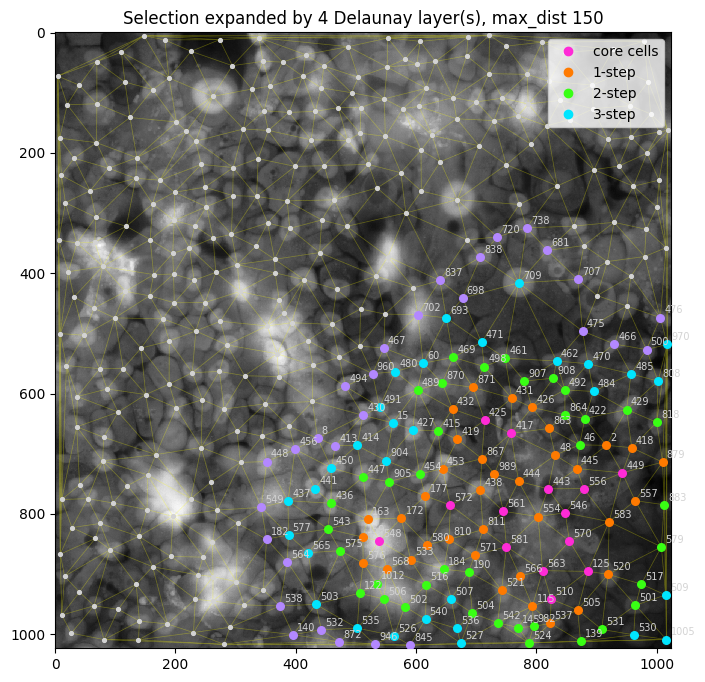

In [150]:
picked_ce = 10
ce_df = df_ce_filt[df_ce_filt['cl_id'] == picked_ce]

display(ce_df)

n_frame_show = 24
n_layers = 4
max_dist = 150

test_ce_df = ce_df[ce_df['t'] == n_frame_show]
whole_ce_df = df_arcos_data[df_arcos_data['t'] == n_frame_show]

display(test_ce_df)
picked_track = test_ce_df['track_id']

test, test_tri = delaunay_per_frame(whole_ce_df, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

# prepare for display with plot_layers function
test_layers = test[["vertex", "layer", "x", "y", "track_id"]]

fig, ax = plot_layers(test_tri.points, test_tri, test_layers, image=np_erk_show, labels="track_id")
ax.set_title(f"Selection expanded by {n_layers} Delaunay layer(s), max_dist {max_dist}")
plt.show()

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 94 182 192]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 180 190]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 92 179 189]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 91 178 187]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 177 186]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 89 176 184]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 90 176 184]
picked track IDs: [561, 443, 546]
these 

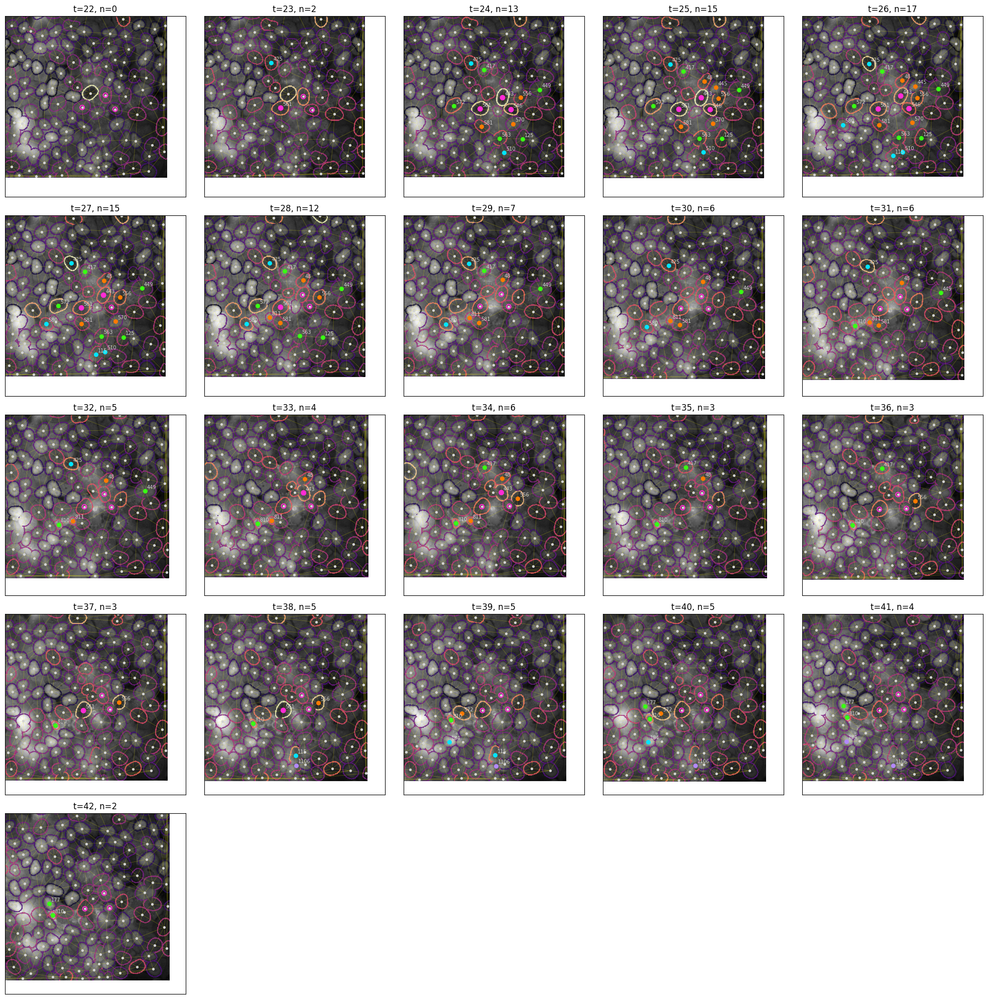

In [151]:
frames = range(22, 43)
ncols = 5
nrows = int(np.ceil(len(frames) / ncols))
zoom = 300                                   # pixels around the selection; None = full frame

picked_track = [561, 443, 546]

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

layer_by_track = None                        # last known {track_id: layer}

for ax, n_frame in zip(axes.ravel(), frames):
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    out, tri = delaunay_per_frame(frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

    if out is not None:                      # track found: remember its neighborhood
        layer_by_track = dict(zip(out['track_id'], out['layer']))
    elif layer_by_track is not None:         # track lost: reuse the last known neighbors
        out, tri = layers_from_tracks(frame, layer_by_track)
        note = " (track lost: last known neighbors)"

    if out is None or out.empty:             # never found yet, or all neighbors gone too
        ax.set_title(f"t={n_frame}: nothing to show")
        ax.axis('off')
        continue

    # attach cnr.bin to the selected cells (matched by track_id within this frame)
    out = out.copy()
    out['cnr.bin'] = out['track_id'].map(frame.set_index('track_id')['cnr.bin'])

    # some freaking zooming feature...
    kw = {}
    if zoom:
        cx, cy = out[['x', 'y']].mean()      # center on the whole selection, not just the coloured cells
        kw = dict(xlim=(cx - zoom, cx + zoom), ylim=(cy + zoom, cy - zoom))   # y reversed for imshow

    # only cells with cnr.bin == 1 get a coloured dot; the rest stay grey
    out_dot = out[out['cnr.bin'] == 1]

    note = f", n={len(out_dot)}"
    plot_layers(tri.points, tri, out_dot, image=np_erk[n_frame],
                ax=ax, legend=False, title=f"t={n_frame}{note}", **kw)

    # pink outline around the picked tracks (uses `out`, so they're outlined even if cnr.bin != 1)
    picked_xy = out.loc[out['track_id'].isin(picked_track), ['x', 'y']]
    ax.scatter(picked_xy['x'], picked_xy['y'], s=40, facecolors='none',
               edgecolors=color_palette[0], linewidths=1.5, zorder=20)
    
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none")

for ax in axes.ravel()[len(frames):]:        # hide unused panels
    ax.axis('off')

plt.tight_layout()
plt.show()

In [152]:
frames = range(5, 51)

picked_track = [561, 443, 546]

# one colour range for ALL frames, computed once before the loop
sl = slice(frames.start, frames.stop)
erk_min, erk_max = np.nanmin(np_erk[sl]), np.nanmax(np_erk[sl])
ring_vals = np_lab_ring_meas[sl]
ring_vals = ring_vals[ring_vals != 0]                  # 0 = background
ring_min, ring_max = np.nanmin(ring_vals), np.nanmax(ring_vals)

rgb_frames = []

layer_by_track = None                        # last known {track_id: layer}

for n_frame in frames:
    fig, ax = plt.subplots(figsize=(6, 6))   # one figure per frame (replaces the montage grid)
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    out, tri = delaunay_per_frame(frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

    if out is not None:                      # track found: remember its neighborhood
        layer_by_track = dict(zip(out['track_id'], out['layer']))
    elif layer_by_track is not None:         # track lost: reuse the last known neighbors
        out, tri = layers_from_tracks(frame, layer_by_track)
        note = " (track lost: last known neighbors)"

    if out is None or out.empty:             # never found yet, or all neighbors gone too
        plt.close(fig)                       # nothing to draw: this frame is left out of the gif
        continue

    # attach cnr.bin to the selected cells (matched by track_id within this frame)
    out = out.copy()
    out['cnr.bin'] = out['track_id'].map(frame.set_index('track_id')['cnr.bin'])

    # only cells with cnr.bin == 1 get a coloured dot; the rest stay grey
    out_dot = out[out['cnr.bin'] == 1]

    note = f", n={len(out_dot)}"
    plot_layers(tri.points, tri, out_dot, image=np_erk[n_frame],
                ax=ax, legend=True, title=f"t={n_frame}{note}",
                vmin=erk_min, vmax=erk_max)                       # same grey scale every frame

    # pink outline around the picked tracks (uses `out`, so they're outlined even if cnr.bin != 1)
    picked_xy = out.loc[out['track_id'].isin(picked_track), ['x', 'y']]
    ax.scatter(picked_xy['x'], picked_xy['y'], s=40, facecolors='none',
               edgecolors="#FF2BD6", linewidths=1.5, zorder=20)
    
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none",
              vmin=ring_min, vmax=ring_max)                       # same ring scale every frame

    ax.set_xlim(600, 1000)
    ax.set_ylim(1000, 600)

    # grab the finished figure as an image, then close it
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    rgb_frames.append(rgb.copy())            # replaces the gif_frames.append(...quantize...) line
    plt.close(fig)

reserved = color_palette + ["#D3D3D3", "#000000", "#FFFFFF"]               # plus light-grey cell dots, black outline, white
reserved_rgb = [tuple(int(c[i:i+2], 16) for i in (1, 3, 5)) for c in reserved]
K = len(reserved_rgb)

pal = Image.fromarray(np.vstack(rgb_frames)).quantize(colors=256 - K)     # palette for everything else
flat = (pal.getpalette() + [0] * 768)[: 3 * (256 - K)]
flat += [v for rgb in reserved_rgb for v in rgb]                          # the exact colors go in the last slots
pal_img = Image.new("P", (1, 1))
pal_img.putpalette(flat)

gif_frames = [Image.fromarray(r).quantize(palette=pal_img, dither=0) for r in rgb_frames]
gif_frames[0].save("ce_10-small.gif", save_all=True, append_images=gif_frames[1:], duration=150, loop=0)

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [103 197 207]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 195 205]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 194 204]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 97 185 195]
picked track IDs: [561, 443, 546]
these 

In [153]:
picked_ce = 10
ce_df = df_ce_filt[df_ce_filt['cl_id'] == picked_ce]

test_ce_df = ce_df[ce_df['t'] == n_frame_show]
whole_ce_df = df_arcos_data[df_arcos_data['t'] == n_frame_show]
#picked_track = test_ce_df['track_id']
picked_track = [561, 443, 546]

frames = range(5, 51)

# one colour range for ALL frames, computed once before the loop
sl = slice(frames.start, frames.stop)
erk_min, erk_max = np.nanmin(np_erk[sl]), np.nanmax(np_erk[sl])
ring_vals = np_lab_ring_meas[sl]
ring_vals = ring_vals[ring_vals != 0]                  # 0 = background
ring_min, ring_max = np.nanmin(ring_vals), np.nanmax(ring_vals)

rgb_frames = []

layer_by_track = None                        # last known {track_id: layer}

for n_frame in frames:
    fig, ax = plt.subplots(figsize=(6, 6))   # one figure per frame (replaces the montage grid)
    frame = df_arcos_data[df_arcos_data['t'] == n_frame]
    out, tri = delaunay_per_frame(frame, picked_track=picked_track, n_layers=n_layers, max_dist=max_dist)

    if out is not None:                      # track found: remember its neighborhood
        layer_by_track = dict(zip(out['track_id'], out['layer']))
    elif layer_by_track is not None:         # track lost: reuse the last known neighbors
        out, tri = layers_from_tracks(frame, layer_by_track)
        note = " (track lost: last known neighbors)"

    if out is None or out.empty:             # never found yet, or all neighbors gone too
        plt.close(fig)                       # nothing to draw: this frame is left out of the gif
        continue

    # attach cnr.bin to the selected cells (matched by track_id within this frame)
    out = out.copy()
    out['cnr.bin'] = out['track_id'].map(frame.set_index('track_id')['cnr.bin'])

    # only cells with cnr.bin == 1 get a coloured dot; the rest stay grey
    out_dot = out[out['cnr.bin'] == 1]

    note = f", n={len(out_dot)}"
    plot_layers(tri.points, tri, out_dot, image=np_erk[n_frame],
                ax=ax, legend=True, title=f"t={n_frame}{note}",
                vmin=erk_min, vmax=erk_max, size=10, legend_max=n_layers+1)

    # pink outline around the picked tracks (uses `out`, so they're outlined even if cnr.bin != 1)
    picked_xy = out.loc[out['track_id'].isin(picked_track), ['x', 'y']]
    ax.scatter(picked_xy['x'], picked_xy['y'], s=6, facecolors='none',
               edgecolors="#FF2BD6", linewidths=0.8, zorder=20)
    
    ax.set_xticks([]); ax.set_yticks([])

    # add cnr rings
    lab = np_lab_ring_meas[n_frame]
    np_lab_show = np.where(lab == 0, np.nan, lab)      # background -> nan so it stays transparent
    ax.imshow(np_lab_show, cmap="magma", alpha=0.8, interpolation="none",
              vmin=ring_min, vmax=ring_max)                       # same ring scale every frame

    # grab the finished figure as an image, then close it
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    rgb_frames.append(rgb.copy())            # replaces the gif_frames.append(...quantize...) line
    plt.close(fig)

reserved = color_palette + ["#D3D3D3", "#000000", "#FFFFFF"]               # plus light-grey cell dots, black outline, white
reserved_rgb = [tuple(int(c[i:i+2], 16) for i in (1, 3, 5)) for c in reserved]
K = len(reserved_rgb)

pal = Image.fromarray(np.vstack(rgb_frames)).quantize(colors=256 - K)     # palette for everything else
flat = (pal.getpalette() + [0] * 768)[: 3 * (256 - K)]
flat += [v for rgb in reserved_rgb for v in rgb]                          # the exact colors go in the last slots
pal_img = Image.new("P", (1, 1))
pal_img.putpalette(flat)

gif_frames = [Image.fromarray(r).quantize(palette=pal_img, dither=0) for r in rgb_frames]
gif_frames[0].save("ce_10-big.gif", save_all=True, append_images=gif_frames[1:], duration=150, loop=0)

picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [108 203 214]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [107 202 213]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [103 197 207]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 195 205]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [102 194 204]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 99 188 198]
picked track IDs: [561, 443, 546]
these correspond to vertex IDs: [ 97 185 195]
picked track IDs: [561, 443, 546]
these 